<a href="https://colab.research.google.com/github/MilaniS-sudo/ASR700-Robotics-Assignment/blob/main/component_a/question3/pid_controller.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Controller correction: 3.02


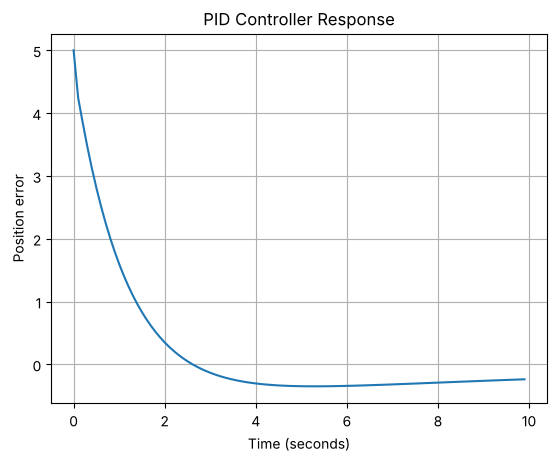

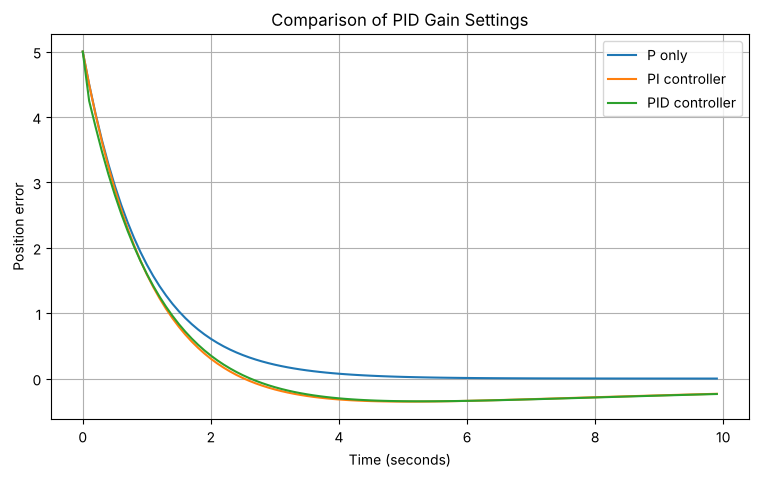

In [1]:

class PIDController:
    def __init__(self, kp, ki, kd):
        self.kp = kp
        self.ki = ki
        self.kd = kd
        self.integral = 0.0
        self.previous_error = 0.0

    def update(self, error, dt):
        if dt <= 0:
            raise ValueError("dt must be greater than zero")

        self.integral += error * dt
        derivative = (
            error - self.previous_error
        ) / dt

        output = (
            self.kp * error
            + self.ki * self.integral
            + self.kd * derivative
        )

        self.previous_error = error
        return output


# Simple test
pid = PIDController(kp=1.0, ki=0.1, kd=0.05)
correction = pid.update(error=2.0, dt=0.1)

print("Controller correction:", correction)

import matplotlib.pyplot as plt

# Simulation settings
dt = 0.1
time_values = []
error_values = []

# Create the controller
pid = PIDController(kp=1.0, ki=0.1, kd=0.05)

# Initial error
error = 5.0
position = 0.0
target = 5.0

for step in range(100):
    current_time = step * dt

    error = target - position
    correction = pid.update(error, dt)

    # Simplified system: correction changes position
    position += correction * dt

    time_values.append(current_time)
    error_values.append(error)

plt.plot(time_values, error_values)
plt.xlabel("Time (seconds)")
plt.ylabel("Position error")
plt.title("PID Controller Response")
plt.grid(True)
plt.show()

import matplotlib.pyplot as plt

gain_settings = [
    (1.0, 0.0, 0.0, "P only"),
    (1.0, 0.1, 0.0, "PI controller"),
    (1.0, 0.1, 0.05, "PID controller")
]

plt.figure(figsize=(9, 5))

for kp, ki, kd, label in gain_settings:
    pid = PIDController(kp, ki, kd)
    position = 0.0
    target = 5.0
    errors = []

    for step in range(100):
        error = target - position
        correction = pid.update(error, 0.1)
        position += correction * 0.1
        errors.append(error)

    plt.plot(
        [step * 0.1 for step in range(100)],
        errors,
        label=label
    )

plt.xlabel("Time (seconds)")
plt.ylabel("Position error")
plt.title("Comparison of PID Gain Settings")
plt.legend()
plt.grid(True)
plt.show()


PID Controller Performance Analysis

The Proportional-Integral-Derivative (PID) controller adjusts the system’s response based on the current error, accumulated error, and rate of change of error.

* Proportional gain (Kp): Responds to the current error. Increasing it can improve response speed but may cause overshoot or instability.
* Integral gain (Ki): Accumulates error over time and can reduce steady-state error.
* Derivative gain (Kd): Responds to changes in error and can help reduce overshoot and improve damping.

Performance measures:

* Rise time: Time taken for the response to approach its target.
* Overshoot: How far the response goes beyond its target.
* Settling time: Time taken for the response to remain close to its target.
* Steady-state error: Remaining difference between the target and the final response.

The current results come from a simplified simulation. Further testing with a robot model in Webots is required to evaluate realistic path tracking and control performance.

In [2]:
import numpy as np

def run_pid_test(kp, ki, kd):
    dt = 0.1
    target = 5.0
    position = 0.0
    pid = PIDController(kp, ki, kd)

    times = []
    positions = []

    for step in range(100):
        time = step * dt
        error = target - position
        correction = pid.update(error, dt)
        position += correction * dt

        times.append(time)
        positions.append(position)

    return np.array(times), np.array(positions), target


times, positions, target = run_pid_test(1.0, 0.1, 0.05)

final_error = abs(target - positions[-1])
overshoot = max(0, (max(positions) - target) / target * 100)

reached_90 = np.where(positions >= 0.9 * target)[0]
rise_time = times[reached_90[0]] if len(reached_90) else None

tolerance = 0.02 * target
settled_time = None

for i in range(len(positions)):
    if np.all(np.abs(positions[i:] - target) <= tolerance):
        settled_time = times[i]
        break

print("Final position:", round(positions[-1], 3))
print("Steady-state error:", round(final_error, 3))
print("Overshoot (%):", round(overshoot, 2))
print("Rise time (seconds):", rise_time)
print("Settling time (seconds):", settled_time)

Final position: 5.234
Steady-state error: 0.234
Overshoot (%): 6.96
Rise time (seconds): 1.8
Settling time (seconds): None


PID Simulation Results and Interpretation

The PID controller was tested using gains (K_p=1.0), (K_i=0.1), and (K_d=0.05), with a target position of 5.0 units.

The final position was 5.234 units, producing a steady-state error of 0.234 units. The measured overshoot was 6.96%, and the rise time was 1.8 seconds. The settling time was not detected because the response did not remain within the specified 2% tolerance for the remainder of the simulation.

These results show that the controller responds to the target but does not settle within the required tolerance during the tested period. Further gain tuning and testing with a realistic robot model are needed. These measurements represent a simplified simulation and are not Webots robot-performance results.

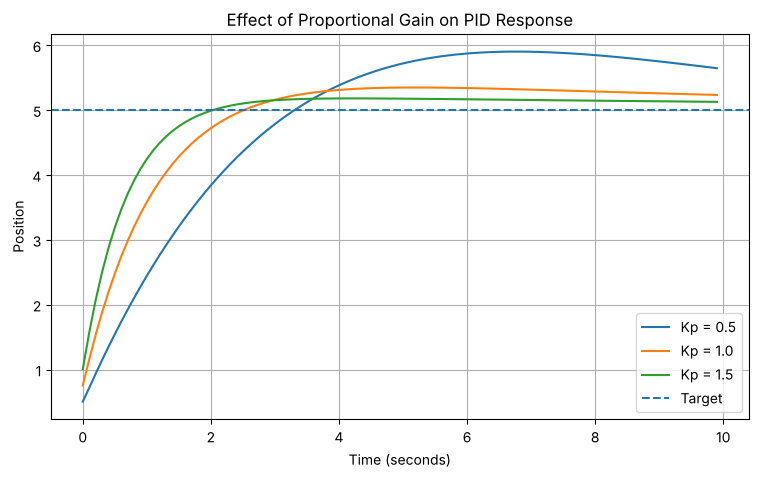

In [3]:
import matplotlib.pyplot as plt

kp_values = [0.5, 1.0, 1.5]
ki = 0.1
kd = 0.05
dt = 0.1
target = 5.0

plt.figure(figsize=(9, 5))

for kp in kp_values:
    pid = PIDController(kp, ki, kd)
    position = 0.0
    positions = []

    for step in range(100):
        error = target - position
        correction = pid.update(error, dt)
        position += correction * dt
        positions.append(position)

    plt.plot(
        [step * dt for step in range(100)],
        positions,
        label=f"Kp = {kp}"
    )

plt.axhline(target, linestyle="--", label="Target")
plt.xlabel("Time (seconds)")
plt.ylabel("Position")
plt.title("Effect of Proportional Gain on PID Response")
plt.legend()
plt.grid(True)
plt.show()

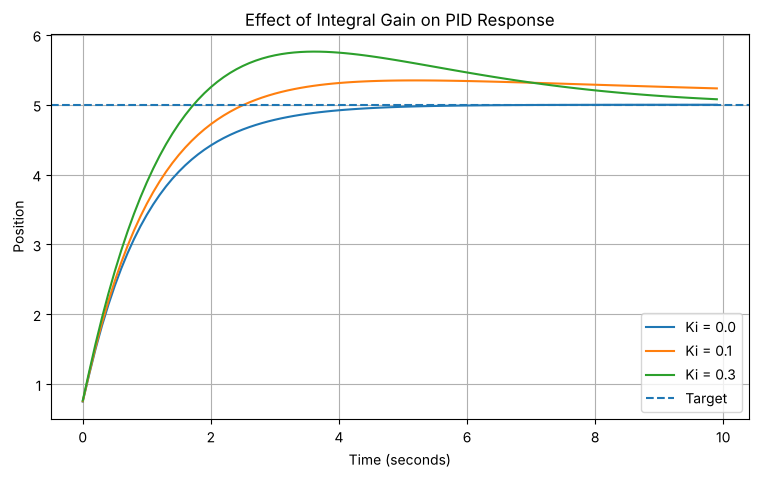

In [4]:
ki_values = [0.0, 0.1, 0.3]
kp = 1.0
kd = 0.05
dt = 0.1
target = 5.0

plt.figure(figsize=(9, 5))

for ki in ki_values:
    pid = PIDController(kp, ki, kd)
    position = 0.0
    positions = []

    for step in range(100):
        error = target - position
        correction = pid.update(error, dt)
        position += correction * dt
        positions.append(position)

    plt.plot(
        [step * dt for step in range(100)],
        positions,
        label=f"Ki = {ki}"
    )

plt.axhline(target, linestyle="--", label="Target")
plt.xlabel("Time (seconds)")
plt.ylabel("Position")
plt.title("Effect of Integral Gain on PID Response")
plt.legend()
plt.grid(True)
plt.show()

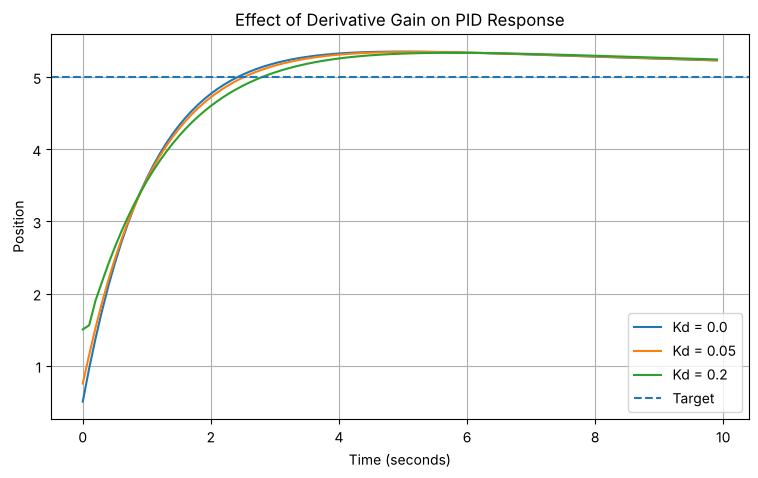

In [5]:
kd_values = [0.0, 0.05, 0.2]
kp = 1.0
ki = 0.1
dt = 0.1
target = 5.0

plt.figure(figsize=(9, 5))

for kd in kd_values:
    pid = PIDController(kp, ki, kd)
    position = 0.0
    positions = []

    for step in range(100):
        error = target - position
        correction = pid.update(error, dt)
        position += correction * dt
        positions.append(position)

    plt.plot(
        [step * dt for step in range(100)],
        positions,
        label=f"Kd = {kd}"
    )

plt.axhline(target, linestyle="--", label="Target")
plt.xlabel("Time (seconds)")
plt.ylabel("Position")
plt.title("Effect of Derivative Gain on PID Response")
plt.legend()
plt.grid(True)
plt.show()

### PID Gain Tuning Analysis

A Proportional\-Integral\-Derivative &#40;PID&#41; controller combines three control actions to regulate a system’s response\. The proportional term responds to the current error, the integral term accumulates error over time, and the derivative term responds to changes in error\. The effectiveness of each term depends on the system being controlled &#40;University of Michigan, 2019&#41;\.

**Proportional gain &#40;&#40;K\_p&#41;&#41;\.** Increasing proportional gain can improve response speed but may also increase overshoot or cause instability\. The appropriate value depends on the system’s behaviour and the desired response &#40;University of Michigan, 2019&#41;\.

**Integral gain &#40;&#40;K\_i&#41;&#41;\.** Integral action accumulates error over time and can reduce steady\-state error\. However, excessive integral gain may increase overshoot and settling time &#40;University of Michigan, n\.d\.; MathWorks, 2026&#41;\.

**Derivative gain &#40;&#40;K\_d&#41;&#41;\.** Derivative action responds to changes in error and can improve damping, potentially reducing overshoot\. Its effectiveness depends on the system dynamics and the other controller gains &#40;University of Michigan, 2019&#41;\.

### PID Performance Measures

Controller performance can be evaluated using rise time, percentage overshoot, settling time and steady\-state error\. These measures help assess response speed, accuracy and transient behaviour &#40;MathWorks, 2026&#41;\.

The simplified simulation used &#40;K\_p=1\.0&#41;, &#40;K\_i=0\.1&#41; and &#40;K\_d=0\.05&#41;, with a target position of 5\.0 units\. The measured rise time was 1\.8 seconds, overshoot was 6\.96%, and the final steady\-state error was 0\.234 units\. Settling time was not detected within the simulation window\.

These measurements are results from the implemented simulation, not values taken from the cited sources\. The response did not remain within the defined 2% settling tolerance for the remainder of the test\. Further tuning and testing are required to improve the response\.

### Limitations and Further Testing

The current experiments use a simplified position model\. They provide an initial comparison of controller gain settings but do not establish the performance of a physical or simulated mobile robot\. The next stage is to integrate the PID controller with the robot’s kinematic model and planned path, then evaluate closed\-loop navigation in Webots\.

In [6]:
import math

def update_robot_position(x, y, theta, linear_velocity,
                          angular_velocity, dt):
    if dt <= 0:
        raise ValueError("dt must be greater than zero")

    new_x = x + linear_velocity * math.cos(theta) * dt
    new_y = y + linear_velocity * math.sin(theta) * dt
    new_theta = theta + angular_velocity * dt
    new_theta = (new_theta + math.pi) % (2 * math.pi) - math.pi

    return new_x, new_y, new_theta


# Test the robot model
x, y, theta = update_robot_position(
    x=0.0,
    y=0.0,
    theta=0.0,
    linear_velocity=1.0,
    angular_velocity=0.5,
    dt=1.0
)

print("Robot x-position:", round(x, 3))
print("Robot y-position:", round(y, 3))
print("Robot heading (radians):", round(theta, 3))

Robot x-position: 1.0
Robot y-position: 0.0
Robot heading (radians): 0.5


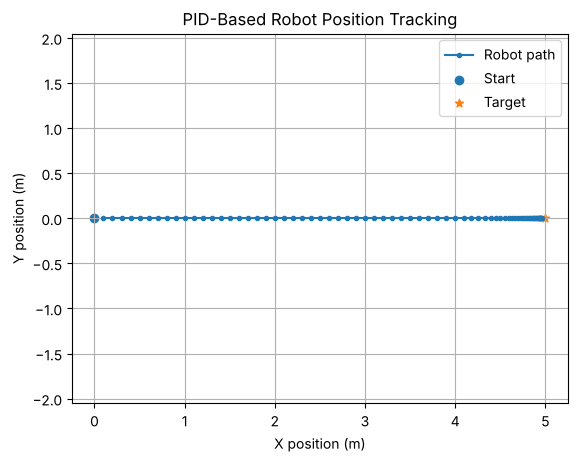

Final position: 4.959 0.0
Remaining distance: 0.046 m


In [7]:
import math
import matplotlib.pyplot as plt

# Robot starting position
x, y, theta = 0.0, 0.0, 0.0

# Target position
target_x, target_y = 5.0, 0.0

# PID controller for forward movement
pid = PIDController(kp=1.0, ki=0.0, kd=0.05)

dt = 0.1
positions_x = []
positions_y = []
errors = []

for step in range(100):
    distance_error = math.sqrt(
        (target_x - x)**2 + (target_y - y)**2
    )

    speed = pid.update(distance_error, dt)
    speed = max(0.0, min(speed, 1.0))  # Limit speed

    x, y, theta = update_robot_position(
        x, y, theta, speed, 0.0, dt
    )

    positions_x.append(x)
    positions_y.append(y)
    errors.append(distance_error)

    if distance_error < 0.05:
        break

plt.plot(positions_x, positions_y, marker=".", label="Robot path")
plt.scatter([0], [0], label="Start")
plt.scatter([target_x], [target_y], marker="*", label="Target")
plt.xlabel("X position (m)")
plt.ylabel("Y position (m)")
plt.title("PID-Based Robot Position Tracking")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()

print("Final position:", round(x, 3), round(y, 3))
print("Remaining distance:", round(distance_error, 3), "m")

PID-Based Robot Position Tracking

A simplified robot tracking simulation was implemented by combining the PID controller with the differential-drive kinematic model. The robot started at coordinates (0.0, 0.0) metres and moved towards the target position (5.0, 0.0) metres.

The final recorded position was (4.959, 0.0) metres, with a remaining distance of 0.046 metres. The simulation used a stopping threshold of 0.05 metres. Since the remaining distance was below this threshold, the stopping condition was satisfied.

These results demonstrate that the controller can guide the simplified model towards a target along a straight line. However, the robot’s heading was fixed, so this test does not demonstrate turning, obstacle avoidance or tracking a complete planned path. Webots integration and further testing are required to evaluate these behaviours.

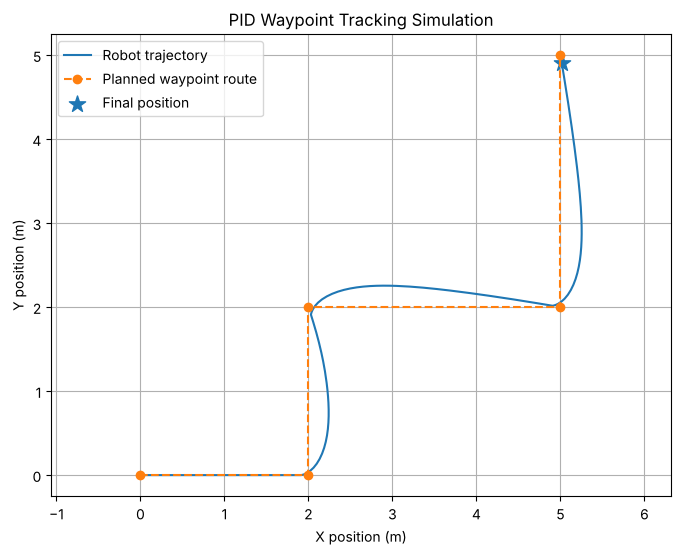

Waypoints reached: 4 of 4
Final position: 5.016 4.902
Final heading (radians): 1.736


In [8]:
import math
import matplotlib.pyplot as plt

# Starting position and heading
x, y, theta = 0.0, 0.0, 0.0

# Ordered waypoints the robot must visit
waypoints = [(2.0, 0.0), (2.0, 2.0), (5.0, 2.0), (5.0, 5.0)]

dt = 0.1
positions_x = [x]
positions_y = [y]
robot_headings = []
heading_error_log = []  # error toward the ACTIVE waypoint

# PID controller for heading
heading_pid = PIDController(kp=2.0, ki=0.0, kd=0.1)

waypoint_index = 0
max_steps = 2000

for step in range(max_steps):
    target_x, target_y = waypoints[waypoint_index]

    dx = target_x - x
    dy = target_y - y
    distance = math.sqrt(dx**2 + dy**2)

    # Move to the next waypoint when close enough
    if distance < 0.1:
        waypoint_index += 1
        if waypoint_index >= len(waypoints):
            break
        heading_pid = PIDController(2.0, 0.0, 0.1)
        continue

    # Calculate the desired heading and heading error
    desired_heading = math.atan2(dy, dx)
    heading_error = (
        desired_heading - theta + math.pi
    ) % (2 * math.pi) - math.pi

    heading_error_log.append(heading_error)

    # PID adjusts the robot's turning speed
    angular_velocity = heading_pid.update(heading_error, dt)
    angular_velocity = max(-1.5, min(angular_velocity, 1.5))

    # Reduce forward speed when the robot faces away from its target
    linear_velocity = min(0.8, 0.8 * distance)
    linear_velocity *= max(0.0, math.cos(heading_error))

    x, y, theta = update_robot_position(
        x, y, theta,
        linear_velocity, angular_velocity, dt
    )

    positions_x.append(x)
    positions_y.append(y)
    robot_headings.append(theta)

# Plot the trajectory and waypoints
plt.figure(figsize=(8, 6))
plt.plot(positions_x, positions_y, label="Robot trajectory")
plt.plot(
    [0.0] + [p[0] for p in waypoints],
    [0.0] + [p[1] for p in waypoints],
    "--o",
    label="Planned waypoint route"
)
plt.scatter([x], [y], marker="*", s=150, label="Final position")
plt.xlabel("X position (m)")
plt.ylabel("Y position (m)")
plt.title("PID Waypoint Tracking Simulation")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()

print("Waypoints reached:", waypoint_index, "of", len(waypoints))
print("Final position:", round(x, 3), round(y, 3))
print("Final heading (radians):", round(theta, 3))

PID Waypoint Tracking Results

A waypoint-tracking simulation was implemented using a PID controller for heading adjustment and a differential-drive kinematic model. The robot was required to visit four waypoints in sequence.

The simulation reported that all four waypoints were reached. The final position was (5.016, 4.902) metres, and the final heading was 1.736 radians. The last waypoint was (5.0, 5.0) metres. The final position was approximately 0.099 metres from this waypoint, satisfying the simulation’s 0.1-metre waypoint threshold.

These results demonstrate waypoint navigation in a simplified Python model. However, reaching the waypoint threshold does not establish the robot’s overall tracking accuracy or stability. Further evaluation should measure trajectory error and test the controller in Webots, where it can interact with a simulated robot and environment.

In [9]:
import numpy as np

# Planned route: start point followed by all waypoints
route = [(0.0, 0.0)] + waypoints

def point_to_segment_distance(px, py, a, b):
    ax, ay = a
    bx, by = b

    dx = bx - ax
    dy = by - ay
    length_squared = dx**2 + dy**2

    if length_squared == 0:
        return np.hypot(px - ax, py - ay)

    t = ((px - ax) * dx + (py - ay) * dy) / length_squared
    t = max(0.0, min(1.0, t))

    nearest_x = ax + t * dx
    nearest_y = ay + t * dy

    return np.hypot(px - nearest_x, py - nearest_y)


path_errors = []

for px, py in zip(positions_x, positions_y):
    distances = [
        point_to_segment_distance(px, py, route[i], route[i + 1])
        for i in range(len(route) - 1)
    ]
    path_errors.append(min(distances))

print("Mean path-tracking error:",
      round(float(np.mean(path_errors)), 3), "m")
print("Maximum path-tracking error:",
      round(float(np.max(path_errors)), 3), "m")

Mean path-tracking error: 0.095 m
Maximum path-tracking error: 0.255 m


Path-Tracking Error Analysis

The robot’s trajectory was evaluated by calculating the shortest distance between each recorded robot position and the line segments forming the planned waypoint route.

The mean path-tracking error was 0.095 m, while the maximum path-tracking error was 0.255 m. These results indicate that the robot generally followed the planned route, although larger deviations occurred at some points during the simulation.

The maximum error was greater than the mean error, showing that tracking accuracy varied along the route. These measurements are based on a simplified Python simulation and do not establish the performance of a robot operating in Webots. Further testing should investigate tracking errors around turns, controller stability, and the effects of sensor feedback and obstacles.

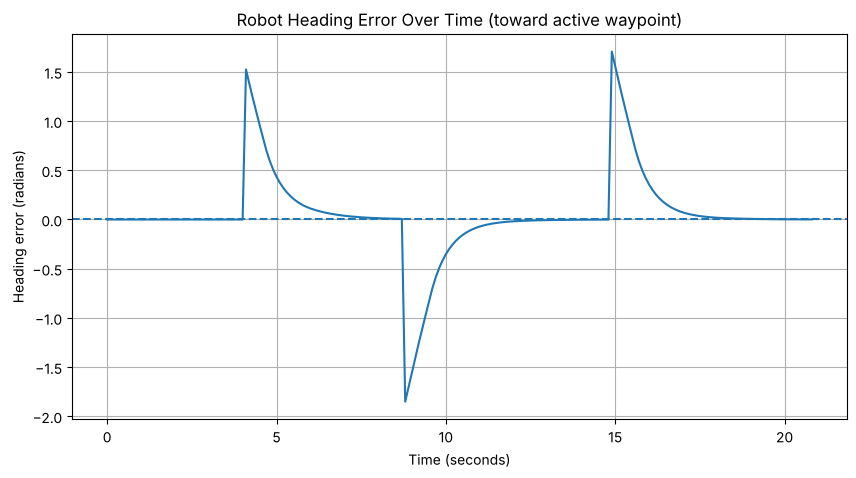

In [10]:
import matplotlib.pyplot as plt
import numpy as np

# Heading error was logged inside the simulation loop, measured toward
# the waypoint the robot was tracking at each step (not the final goal).
heading_errors = np.array(heading_error_log)
time_values = np.arange(len(heading_errors)) * dt

plt.figure(figsize=(10, 5))
plt.plot(time_values, heading_errors)
plt.axhline(0, linestyle="--")
plt.xlabel("Time (seconds)")
plt.ylabel("Heading error (radians)")
plt.title("Robot Heading Error Over Time (toward active waypoint)")
plt.grid(True)
plt.show()

Heading Error Analysis

The heading-error graph shows the difference between the robot's heading and the direction toward the waypoint it is currently tracking. The dashed line marks zero error, where the robot faces the desired direction.

The error stays near zero on each straight segment. Three sharp spikes appear, at roughly 4 s, 9 s and 15 s, each matching a switch to the next waypoint. Because each new segment is a 90° turn, the error jumps to about ±1.5 to 1.8 rad. The spike is larger than 90° because the robot switches waypoint slightly before reaching the corner. The sign of each spike shows the turn direction: positive for a left turn and negative for a right turn.

After each spike, the error decays smoothly to zero within about 2 seconds, with no visible overshoot or oscillation. This indicates that the heading controller (Kp = 2.0, Kd = 0.1) is stable and well damped for this route. The angular-velocity limit of ±1.5 rad/s produces the near-linear first part of each decay, before the exponential tail.

This analysis is based on a simplified Python simulation without sensor noise or wheel slip. Testing in Webots is still required.